# 02 · Exploración: cifras nacionales y gráficas para la presentación

Con la tabla persona-año del notebook 01 respondemos preguntas descriptivas:
¿cuántos meses al año trabaja un contratista?, ¿cambia entre años?, ¿hay brecha de género?,
¿dónde están?, ¿es distinto trabajar con una entidad nacional que con una territorial?,
¿cuándo se firman los contratos? y ¿cuántos cotizan sobre el mínimo?

Cada gráfica se guarda en `outputs/figs/` a 200 dpi, con un título que dice el hallazgo.

In [1]:
# --- Configuración común: rutas (Colab o local), constantes de ley y estilo de gráficas ---
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from cycler import cycler
warnings.filterwarnings('ignore')

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ_DRIVE = Path('/content/drive/MyDrive/Proyecto Final SECOP')
    DATA_DIR = RAIZ_DRIVE / 'data' / 'processed'
    assert DATA_DIR.exists(), (f'No encuentro {DATA_DIR}. Sube la carpeta "Proyecto Final SECOP" (con data/processed/'
                               'secop_ps_AAAA.parquet, ver README.md) a la raíz de "Mi unidad" y vuelve a ejecutar.')
    # Las salidas quedan en "Proyecto Final SECOP/proyecto_secop/" para que las rutas relativas funcionen
    CARPETA_NB = RAIZ_DRIVE / 'proyecto_secop' / 'notebooks'
    CARPETA_NB.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA_NB)
else:
    # Local: variable de entorno SECOP_DATA o, si no existe, la estructura del README relativa al notebook
    # (proyecto_secop/ junto a data/, o proyecto_secop/ dentro de la carpeta del proyecto).
    candidatos = [os.environ.get('SECOP_DATA'), '../data/processed', '../../data/processed']
    DATA_DIR = next((Path(c) for c in candidatos if c and Path(c).exists()), None)
    assert DATA_DIR is not None, ('No encuentro los parquet. Define la variable de entorno SECOP_DATA con la ruta a '
                                  'data/processed (ver README.md) o ubica proyecto_secop/ junto a la carpeta data/.')

# Salidas con rutas relativas a la carpeta notebooks/
OUT = Path('../outputs'); FIGS = OUT / 'figs'; TABLAS = OUT / 'tablas'; INTER = Path('../data_intermedia')
for _p in (FIGS, TABLAS, INTER):
    _p.mkdir(parents=True, exist_ok=True)
RESULTADOS = OUT / 'resultados.json'

# Constantes de ley (no son datos externos: salario mínimo decretado y regla del IBC del independiente)
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000,
         2024: 1_300_000, 2025: 1_423_500, 2026: 1_750_905}   # 2026: Decreto 1469 de 2025 (verificado)
FRACCION_IBC = 0.40          # el IBC del independiente es el 40% del honorario mensual
SEMANAS_PENSION = 1300       # semanas exigidas para pensión de vejez (Colpensiones)
DIAS_MES = 30.4375           # 365,25 / 12, para pasar duración en días a meses
SEMILLA = 42

# --- Estilo de gráficas para diapositivas: sobrio, letra grande, sin adornos ---
COLOR = {'azul': '#2a78d6', 'naranja': '#eb6834', 'aqua': '#1baf7a', 'amarillo': '#eda100',
         'magenta': '#e87ba4', 'verde': '#008300', 'violeta': '#6250d6', 'rojo': '#e34948',
         'gris': '#9b9a95', 'gris_claro': '#d9d8d3', 'tinta': '#0b0b0b', 'tinta2': '#52514e'}
SERIE = [COLOR[c] for c in ('azul', 'naranja', 'aqua', 'amarillo', 'magenta', 'verde', 'violeta', 'rojo')]
mpl.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.family': 'DejaVu Sans',
    'font.size': 15, 'axes.titlesize': 20, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 34, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.frameon': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9b9a95', 'axes.labelcolor': COLOR['tinta2'], 'xtick.color': COLOR['tinta2'],
    'ytick.color': COLOR['tinta2'], 'text.color': COLOR['tinta'], 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#ebeae6', 'grid.linewidth': 0.9, 'axes.axisbelow': True, 'lines.linewidth': 2.5,
    'axes.prop_cycle': cycler(color=SERIE)})

def titulo(ax, texto, sub=None):
    """Título que cuenta el hallazgo + subtítulo gris con el detalle."""
    ax.set_title(texto, loc='left')
    if sub:
        ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=13, color=COLOR['tinta2'], va='bottom')

def fuente(fig, texto='Fuente: SECOP II (datos.gov.co), contratos de prestación de servicios a personas naturales.'):
    fig.text(0.01, -0.02, texto, fontsize=10.5, color=COLOR['gris'], ha='left', va='top')

def guardar(fig, nombre):
    ruta = FIGS / f'{nombre}.png'
    fig.savefig(ruta)
    print('Figura guardada:', ruta)

def num(x, d=0):
    """Formato numérico en español: 1.234.567,8"""
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')

def pesos_millones(x, pos=None):
    return f'${num(x/1e6, 1)}M'

def pct(x, d=1):
    return f'{num(100*x, d)}%'

def guardar_resultados(seccion, datos):
    """Agrega/actualiza una sección en outputs/resultados.json."""
    todo = json.loads(RESULTADOS.read_text()) if RESULTADOS.exists() else {}
    todo[seccion] = datos
    RESULTADOS.write_text(json.dumps(todo, ensure_ascii=False, indent=2, default=float))
    print(f'resultados.json -> sección "{seccion}" actualizada')

print('Colab:', EN_COLAB, '| DATA_DIR:', DATA_DIR, '| existe:', DATA_DIR.exists())

Colab: False | DATA_DIR: ../data/processed | existe: True


In [2]:
pa = pd.read_parquet(INTER / 'persona_anio_2022_2025.parquet')
print(pa.shape)
R = {}   # cifras para resultados.json

(1825478, 30)


## 1. ¿Cuántos meses al año tiene contrato una persona? (2024)

Figura guardada: ../outputs/figs/02_distribucion_meses_cubiertos_2024.png


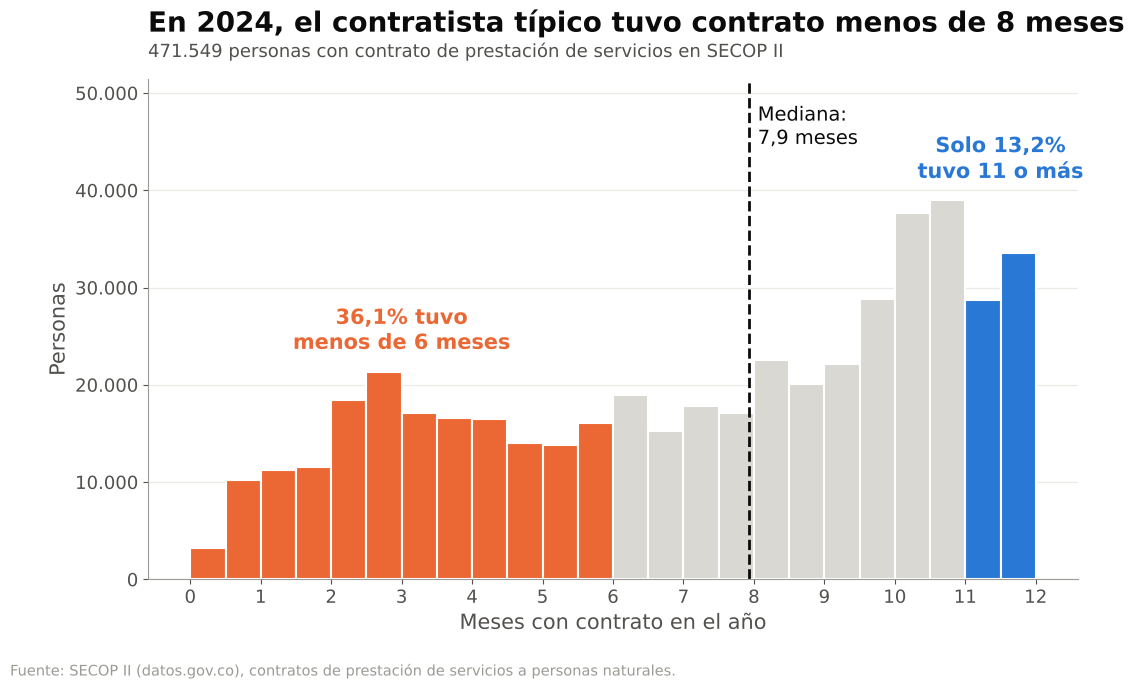

In [3]:
p24 = pa[pa.anio == 2024]
med = p24.meses_cubiertos.median()
R['2024'] = {'personas': int(len(p24)), 'meses_mediana': float(med),
             'meses_p25': float(p24.meses_cubiertos.quantile(.25)), 'meses_p75': float(p24.meses_cubiertos.quantile(.75)),
             'pct_11_mas': float((p24.meses_cubiertos >= 11).mean()), 'pct_menos_6': float((p24.meses_cubiertos < 6).mean()),
             'honorario_mediano': float(p24.honorario_mensual_mediano.median()),
             'pct_cotiza_minimo': float(p24.cotiza_minimo.mean()), 'semanas_mediana': float(p24.semanas_cotizables.median())}
R['2024']['anios_para_1300'] = SEMANAS_PENSION / R['2024']['semanas_mediana']

fig, ax = plt.subplots(figsize=(12, 6.5))
bins = np.arange(0, 12.5, 0.5)
n, b, patches = ax.hist(p24.meses_cubiertos, bins=bins, color=COLOR['gris_claro'], edgecolor='white', linewidth=1.5)
for pt, izq in zip(patches, b[:-1]):
    if izq < 6: pt.set_facecolor(COLOR['naranja'])
    elif izq >= 11: pt.set_facecolor(COLOR['azul'])
ytop = n.max() * 1.32
ax.set_ylim(0, ytop)
ax.axvline(med, color=COLOR['tinta'], lw=2, ls='--')
ax.text(med + 0.12, ytop * 0.95, f'Mediana:\n{num(med,1)} meses', ha='left', va='top', fontsize=14)
ax.text(3, n[:12].max() * 1.08, f'{pct(R["2024"]["pct_menos_6"])} tuvo\nmenos de 6 meses', color=COLOR['naranja'],
        fontsize=15, fontweight='bold', ha='center', va='bottom')
ax.text(11.5, n.max() * 1.04, f'Solo {pct(R["2024"]["pct_11_mas"])}\ntuvo 11 o más', color=COLOR['azul'],
        fontsize=15, fontweight='bold', ha='center', va='bottom')
ax.set_xlabel('Meses con contrato en el año'); ax.set_ylabel('Personas')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: num(x)))
ax.set_xticks(range(0, 13))
titulo(ax, 'En 2024, el contratista típico tuvo contrato menos de 8 meses',
       f'{num(len(p24))} personas con contrato de prestación de servicios en SECOP II')
fuente(fig); guardar(fig, '02_distribucion_meses_cubiertos_2024'); plt.show()

## 2. Evolución por año (2022–2025)

,personas,meses_mediana,semanas_mediana,honorario_mediano,pct_cotiza_minimo,Menos de 6 meses,6 a 11 meses,11 meses o más,anios_para_1300
anio,,,,,,,,,
2022,402755,9.995,43.429,3352473.214,0.311,0.285,0.461,0.254,29.934
2023,437494,9.271,40.286,3556111.004,0.363,0.254,0.569,0.177,32.270
2024,471549,7.934,34.571,3951553.759,0.374,0.361,0.508,0.132,37.603
2025,513680,9.041,39.286,4059355.402,0.400,0.270,0.555,0.176,33.091


Figura guardada: ../outputs/figs/02_evolucion_tramos_meses_por_anio.png


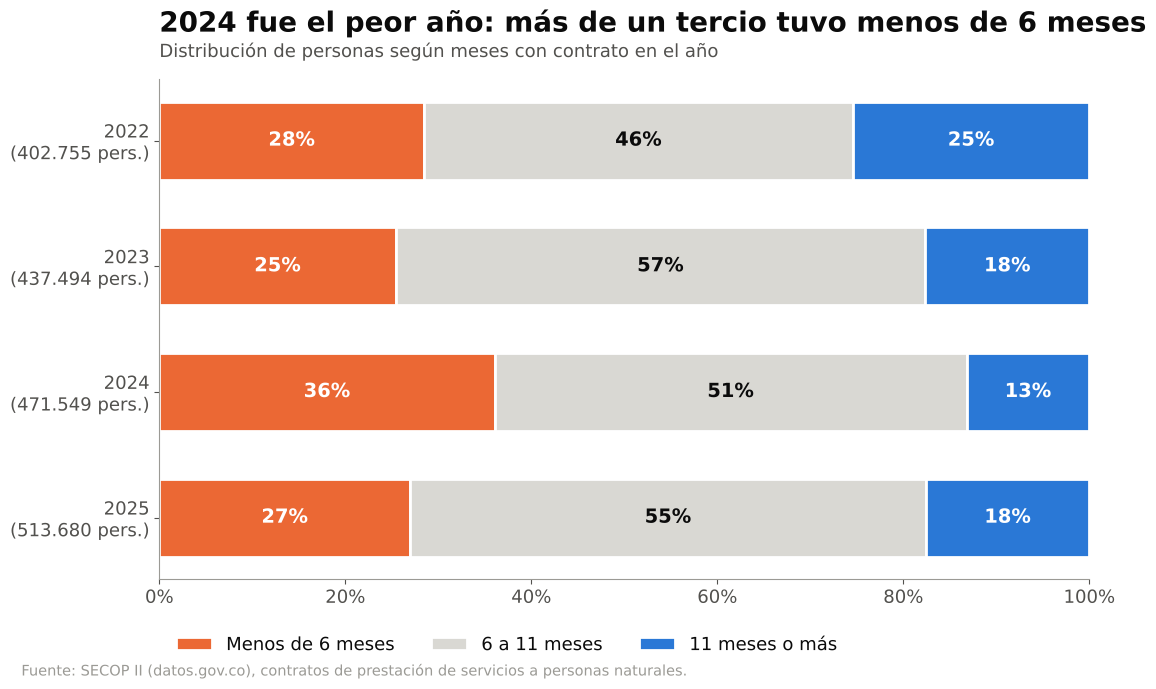

In [4]:
def tramo(m):
    return pd.cut(m, [-0.01, 6 - 1e-9, 11 - 1e-9, 12.01], labels=['Menos de 6 meses', '6 a 11 meses', '11 meses o más'])
ev = pa.assign(tramo=tramo(pa.meses_cubiertos)).groupby(['anio', 'tramo'], observed=True).size().unstack()
ev = ev.div(ev.sum(1), axis=0)
por_anio = pa.groupby('anio').agg(personas=('id_persona', 'size'), meses_mediana=('meses_cubiertos', 'median'),
                                  semanas_mediana=('semanas_cotizables', 'median'),
                                  honorario_mediano=('honorario_mensual_mediano', 'median'),
                                  pct_cotiza_minimo=('cotiza_minimo', 'mean'))
por_anio = por_anio.join(ev)
por_anio['anios_para_1300'] = SEMANAS_PENSION / por_anio.semanas_mediana
por_anio.to_csv(TABLAS / '02_evolucion_por_anio.csv')
display(por_anio.round(3))

fig, ax = plt.subplots(figsize=(12, 6.5))
colores = [COLOR['naranja'], COLOR['gris_claro'], COLOR['azul']]
izq = np.zeros(len(ev))
y = np.arange(len(ev))[::-1]
for col, c in zip(ev.columns, colores):
    ax.barh(y, ev[col].values, left=izq, color=c, edgecolor='white', linewidth=2, height=0.62, label=col)
    for yi, l, w in zip(y, izq, ev[col].values):
        ax.text(l + w / 2, yi, pct(w, 0), ha='center', va='center', fontsize=14,
                color='white' if c != COLOR['gris_claro'] else COLOR['tinta'], fontweight='bold')
    izq += ev[col].values
ax.set_yticks(y); ax.set_yticklabels([f'{a}\n({num(por_anio.personas[a])} pers.)' for a in ev.index])
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlim(0, 1); ax.grid(False)
ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, -0.08))
titulo(ax, '2024 fue el peor año: más de un tercio tuvo menos de 6 meses',
       'Distribución de personas según meses con contrato en el año')
fuente(fig); guardar(fig, '02_evolucion_tramos_meses_por_anio'); plt.show()

**Lectura.** 2022 se ve "mejor" porque, por la Ley de Garantías, muchas entidades firmaron en enero contratos
largos, hasta diciembre. 2024 coincide con el primer año de los nuevos gobiernos locales, que tardan en arrancar a
contratar (lo vemos abajo en la serie mensual). En ningún año la mitad de los contratistas llega a 11 meses.

## 3. Género: ¿hay brecha en meses y en honorario?
Usamos solo personas con género Mujer u Hombre (el 22% de las filas persona-año no tiene género definido).

,anio,genero,meses_mediana,meses_media,honorario_mediano,pct_cotiza_minimo,personas
0,2022,Hombre,9.436,7.825,3151477.183,0.345,124854
1,2022,Mujer,9.633,7.963,3124851.540,0.341,159281
2,2023,Hombre,8.844,7.751,3424218.750,0.394,144598
3,2023,Mujer,9.008,7.907,3348125.000,0.395,187712
4,2024,Hombre,7.344,6.931,3810909.627,0.404,165475
5,2024,Mujer,7.443,6.993,3772872.713,0.401,212300
6,2025,Hombre,8.778,7.736,3997212.483,0.427,187382
7,2025,Mujer,8.975,7.844,3921754.808,0.430,235315


Brecha de honorario mediano (1 - M/H):
anio
2022    0.008
2023    0.022
2024    0.010
2025    0.019
dtype: float64


genero,Hombre,Mujer,brecha_1_menos_M_sobre_H,pct_mujeres,personas
tipo_objeto,,,,,
Apoyo a la gestión,2522889.500,2477974.169,0.018,0.539,107466
Otro,2876970.505,2685022.321,0.067,0.551,65769
Profesional,4823089.688,4560628.411,0.054,0.578,204540


Figura guardada: ../outputs/figs/02_brecha_genero_meses_honorario.png


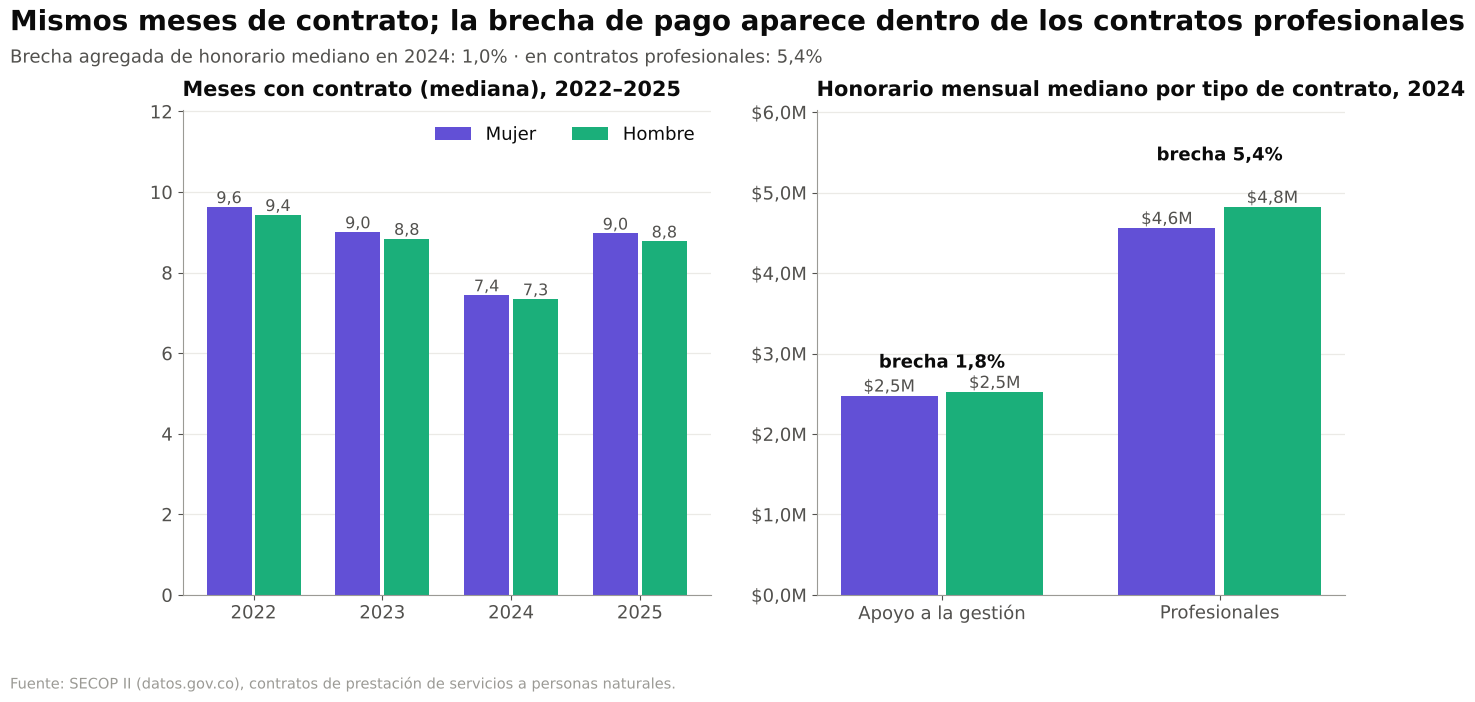

In [5]:
g = pa[pa.genero.isin(['Mujer', 'Hombre'])]
gen = g.groupby(['anio', 'genero'], observed=True).agg(meses_mediana=('meses_cubiertos', 'median'),
                                                       meses_media=('meses_cubiertos', 'mean'),
                                                       honorario_mediano=('honorario_mensual_mediano', 'median'),
                                                       pct_cotiza_minimo=('cotiza_minimo', 'mean'),
                                                       personas=('id_persona', 'size')).reset_index()
gen.to_csv(TABLAS / '02_genero_por_anio.csv', index=False)
display(gen.round(3))
piv_h = gen.pivot(index='anio', columns='genero', values='honorario_mediano')
piv_m = gen.pivot(index='anio', columns='genero', values='meses_mediana')
brecha_h = 1 - piv_h.Mujer / piv_h.Hombre
print('Brecha de honorario mediano (1 - M/H):'); print(brecha_h.round(3))

# ¿La brecha se explica por el tipo de contrato? Comparamos dentro de contratos "profesionales" y de "apoyo"
g24 = g[g.anio == 2024].copy()
g24['tipo_objeto'] = np.select([g24.share_objeto_profesional >= 0.5, g24.share_objeto_apoyo >= 0.5],
                               ['Profesional', 'Apoyo a la gestión'], 'Otro')
brecha_tipo = g24.groupby(['tipo_objeto', 'genero'], observed=True).honorario_mensual_mediano.median().unstack()
brecha_tipo['brecha_1_menos_M_sobre_H'] = 1 - brecha_tipo.Mujer / brecha_tipo.Hombre
brecha_tipo['pct_mujeres'] = g24.groupby('tipo_objeto').genero.apply(lambda s: (s == 'Mujer').mean())
brecha_tipo['personas'] = g24.groupby('tipo_objeto').size()
brecha_tipo.to_csv(TABLAS / '02_brecha_genero_por_tipo_objeto_2024.csv')
display(brecha_tipo.round(3))

fig, axs = plt.subplots(1, 2, figsize=(15, 6.3))
anios = piv_m.index.values; w = 0.38
ax = axs[0]
for i, (gname, c) in enumerate([('Mujer', COLOR['violeta']), ('Hombre', COLOR['aqua'])]):
    xs = np.arange(len(anios)) + (i - 0.5) * w
    ax.bar(xs, piv_m[gname].values, width=w - 0.03, color=c, label=gname)
    for xx, v in zip(xs, piv_m[gname].values):
        ax.text(xx, v, num(v, 1), ha='center', va='bottom', fontsize=11.5, color=COLOR['tinta2'])
ax.set_xticks(np.arange(len(anios))); ax.set_xticklabels(anios)
ax.set_title('Meses con contrato (mediana), 2022–2025', fontsize=15, pad=10)
ax.set_ylim(0, piv_m.values.max() * 1.25)
ax.legend(loc='upper right', ncol=2)
ax = axs[1]
tipos = ['Apoyo a la gestión', 'Profesional']
for i, (gname, c) in enumerate([('Mujer', COLOR['violeta']), ('Hombre', COLOR['aqua'])]):
    xs = np.arange(len(tipos)) + (i - 0.5) * w
    vals = brecha_tipo.loc[tipos, gname].values
    ax.bar(xs, vals, width=w - 0.03, color=c, label=gname)
    for xx, v in zip(xs, vals):
        ax.text(xx, v, pesos_millones(v), ha='center', va='bottom', fontsize=12, color=COLOR['tinta2'])
for j, t in enumerate(tipos):
    ax.text(j, brecha_tipo.loc[t, ['Mujer', 'Hombre']].max() * 1.12, f'brecha {pct(brecha_tipo.loc[t, "brecha_1_menos_M_sobre_H"])}',
            ha='center', fontsize=13, fontweight='bold')
ax.set_ylim(0, brecha_tipo.loc[tipos, ['Mujer', 'Hombre']].values.max() * 1.25)
ax.set_xticks(range(len(tipos))); ax.set_xticklabels(['Apoyo a la gestión', 'Profesionales'])
ax.yaxis.set_major_formatter(FuncFormatter(pesos_millones))
ax.set_title('Honorario mensual mediano por tipo de contrato, 2024', fontsize=15, pad=10)
b24 = brecha_h.loc[2024]
fig.suptitle('Mismos meses de contrato; la brecha de pago aparece dentro de los contratos profesionales',
             x=0.01, ha='left', fontsize=20, fontweight='bold', y=1.04)
fig.text(0.01, 0.955, f'Brecha agregada de honorario mediano en 2024: {pct(b24)} · en contratos profesionales: '
         f'{pct(brecha_tipo.loc["Profesional", "brecha_1_menos_M_sobre_H"])}', fontsize=13, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '02_brecha_genero_meses_honorario'); plt.show()
R['genero'] = {'brecha_honorario_mediano_por_anio': brecha_h.to_dict(),
               'meses_mediana': piv_m.to_dict(), 'honorario_mediano': piv_h.to_dict(),
               'brecha_2024_por_tipo_objeto': brecha_tipo.brecha_1_menos_M_sobre_H.to_dict(),
               'pct_mujeres_por_tipo_objeto_2024': brecha_tipo.pct_mujeres.to_dict(),
               'pct_persona_anio_sin_genero': float((pa.genero == 'No Definido').mean())}

**Lectura.** Mujeres y hombres tienen prácticamente los mismos meses cubiertos (las mujeres, incluso un poco más).
En el agregado, la brecha de honorario es pequeña (1–2%). Esto es un **efecto de composición**: las mujeres están
más representadas en los contratos profesionales, que pagan más, y eso compensa en parte la brecha. **Dentro** de
cada tipo de contrato la brecha es mayor: 1,8% en apoyo a la gestión, 5,4% en profesionales y 6,7% en "Otro" (ver
la tabla). La figura no muestra "Otro" porque es una mezcla heterogénea de objetos: lo que no menciona ni
"profesional" ni "apoyo a la gestión". No es una paradoja de Simpson porque la brecha no cambia de signo.
Esto es descriptivo: no controla profesión, experiencia, cargo ni entidad.

## 4. ¿Dónde están los contratistas? Top departamentos (2024)

Figura guardada: ../outputs/figs/02_top_departamentos_2024.png


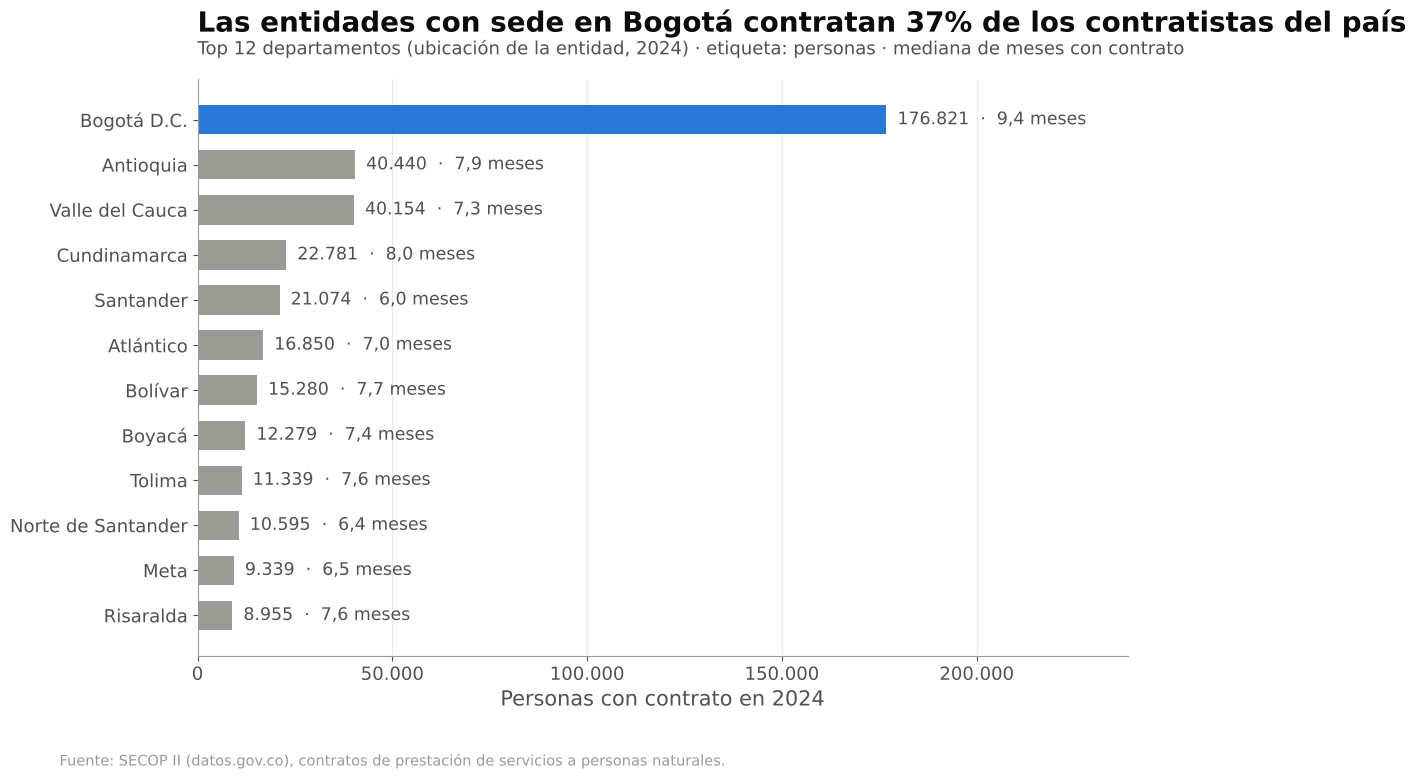

In [6]:
dep = p24[p24.departamento_modal != 'No Definido'].groupby('departamento_modal', observed=True).agg(
    personas=('id_persona', 'size'), meses_mediana=('meses_cubiertos', 'median'),
    honorario_mediano=('honorario_mensual_mediano', 'median'), pct_cotiza_minimo=('cotiza_minimo', 'mean'),
    pct_11_mas=('meses_cubiertos', lambda x: (x >= 11).mean())).sort_values('personas', ascending=False)
dep['pct_personas'] = dep.personas / len(p24)
dep.to_csv(TABLAS / '02_departamentos_2024.csv')
top = dep.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 7.5))
nombres = [n.replace('Distrito Capital de Bogotá', 'Bogotá D.C.') for n in top.index]
ax.barh(nombres, top.personas, color=[COLOR['azul'] if i == len(top) - 1 else COLOR['gris'] for i in range(len(top))], height=0.65)
for i, (v, m) in enumerate(zip(top.personas, top.meses_mediana)):
    ax.text(v, i, f'  {num(v)}  ·  {num(m,1)} meses', va='center', fontsize=12.5, color=COLOR['tinta2'])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: num(x))); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, top.personas.max() * 1.35); ax.set_xlabel('Personas con contrato en 2024')
bog = dep.loc['Distrito Capital de Bogotá']
titulo(ax, f'Las entidades con sede en Bogotá contratan {pct(bog.pct_personas,0)} de los contratistas del país',
       'Top 12 departamentos (ubicación de la entidad, 2024) · etiqueta: personas · mediana de meses con contrato')
fuente(fig); guardar(fig, '02_top_departamentos_2024'); plt.show()
R['departamentos_2024_top10'] = dep.head(10)[['personas', 'pct_personas', 'meses_mediana', 'honorario_mediano']].to_dict('index')

## 5. Nacional vs territorial
Clasificamos a cada persona-año según la mayoría de sus contratos: **nacional** si ≥ 50% son con entidades del
orden nacional; **territorial** en otro caso (incluye corporaciones autónomas).

,anio,orden_persona,personas,meses_mediana,pct_11_mas,honorario_mediano,pct_cotiza_minimo
0,2022,Nacional,132046,10.521,0.337,3931988.994,0.193
1,2022,Territorial,270709,9.567,0.214,3006172.840,0.368
2,2023,Nacional,147636,9.764,0.202,4133359.101,0.208
3,2023,Territorial,289858,9.041,0.164,3097025.872,0.442
4,2024,Nacional,177286,9.213,0.173,4487925.433,0.247
5,2024,Territorial,294263,7.279,0.108,3509664.039,0.451
6,2025,Nacional,180822,9.896,0.204,4662054.149,0.238
7,2025,Territorial,332858,8.745,0.161,3613660.887,0.488


Figura guardada: ../outputs/figs/02_nacional_vs_territorial.png


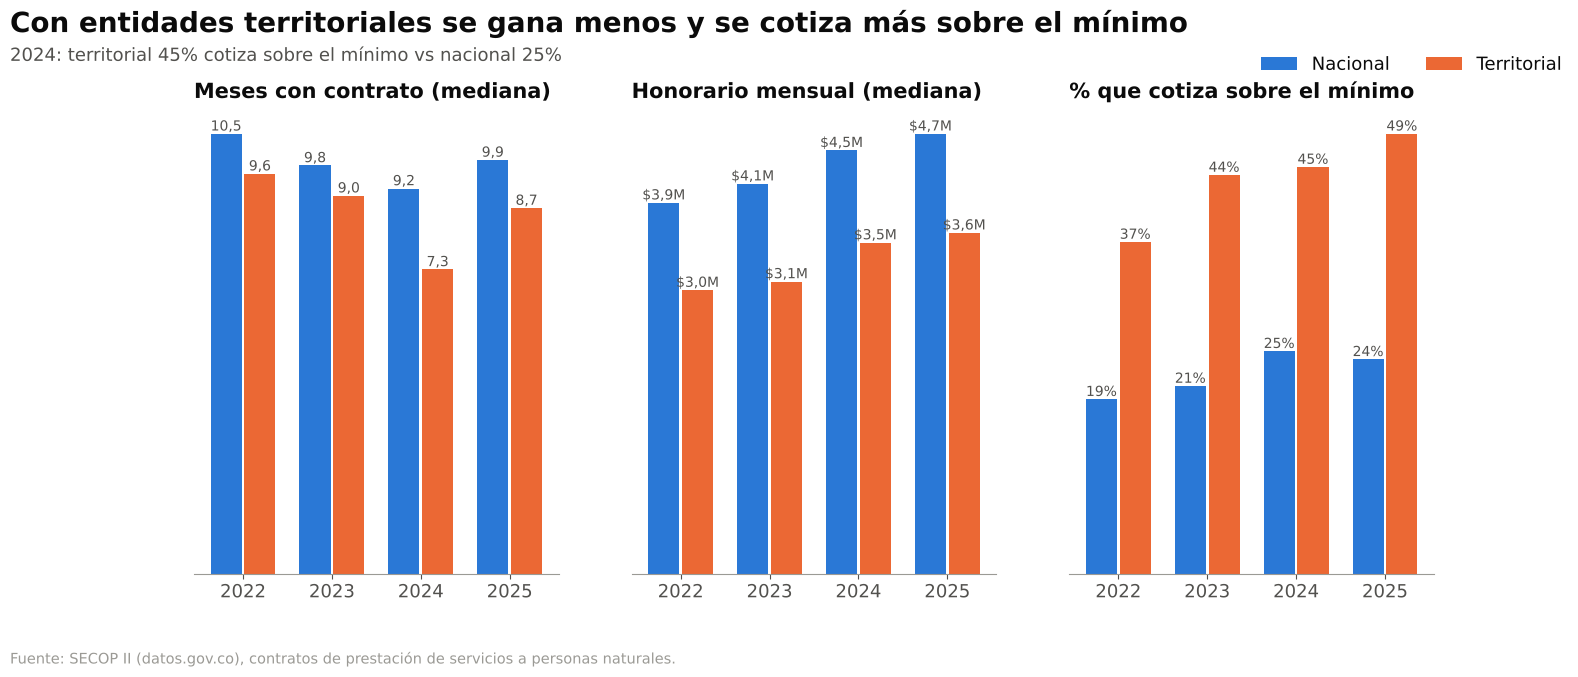

In [7]:
pa['orden_persona'] = np.where(pa.share_entidad_nacional >= 0.5, 'Nacional', 'Territorial')
nt = pa.groupby(['anio', 'orden_persona']).agg(personas=('id_persona', 'size'), meses_mediana=('meses_cubiertos', 'median'),
                                               pct_11_mas=('meses_cubiertos', lambda x: (x >= 11).mean()),
                                               honorario_mediano=('honorario_mensual_mediano', 'median'),
                                               pct_cotiza_minimo=('cotiza_minimo', 'mean')).reset_index()
nt.to_csv(TABLAS / '02_nacional_vs_territorial.csv', index=False)
display(nt.round(3))
fig, axs = plt.subplots(1, 3, figsize=(16, 6))
specs = [('meses_mediana', 'Meses con contrato (mediana)', lambda v: num(v, 1)),
         ('honorario_mediano', 'Honorario mensual (mediana)', pesos_millones),
         ('pct_cotiza_minimo', '% que cotiza sobre el mínimo', lambda v: pct(v, 0))]
for ax, (col, lab, f) in zip(axs, specs):
    piv = nt.pivot(index='anio', columns='orden_persona', values=col)
    for i, (o, c) in enumerate([('Nacional', COLOR['azul']), ('Territorial', COLOR['naranja'])]):
        xs = np.arange(len(piv)) + (i - 0.5) * 0.38
        ax.bar(xs, piv[o], width=0.35, color=c, label=o)
        for xx, v in zip(xs, piv[o]):
            ax.text(xx, v, f(v), ha='center', va='bottom', fontsize=10, color=COLOR['tinta2'])
    ax.set_xticks(range(len(piv))); ax.set_xticklabels(piv.index); ax.set_title(lab, fontsize=15, pad=10)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
fig.legend(*axs[0].get_legend_handles_labels(), loc='upper right', ncol=2, bbox_to_anchor=(0.99, 1.0))
n24 = nt[nt.anio == 2024].set_index('orden_persona')
fig.suptitle('Con entidades territoriales se gana menos y se cotiza más sobre el mínimo',
             x=0.01, ha='left', fontsize=20, fontweight='bold', y=1.05)
fig.text(0.01, 0.965, f'2024: territorial {pct(n24.loc["Territorial","pct_cotiza_minimo"],0)} cotiza sobre el mínimo vs '
         f'nacional {pct(n24.loc["Nacional","pct_cotiza_minimo"],0)}', fontsize=13, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '02_nacional_vs_territorial'); plt.show()
R['nacional_vs_territorial'] = {f'{r.anio}_{r.orden_persona}': {k: float(getattr(r, k)) for k in
                                ['personas', 'meses_mediana', 'pct_11_mas', 'honorario_mediano', 'pct_cotiza_minimo']}
                                for r in nt.itertuples()}

## 6. ¿Cuándo se firman los contratos? Serie mensual 2020–2026
Aquí usamos todos los contratos (sin limpiar), contados por mes de firma.

Contratos firmados en enero:
fecha_de_firma
2020-01-01     38604
2021-01-01     64735
2022-01-01    279469
2023-01-01    113876
2024-01-01     90881
2025-01-01    134252
2026-01-01    455420
Name: count, dtype: int64
                 enero  febrero mes_pico_ene_feb
fecha_de_firma                                  
2020             38604    43864          febrero
2021             64735    69296          febrero
2022            279469    32293            enero
2023            113876   131721          febrero
2024             90881   103952          febrero
2025            134252   145675          febrero
2026            455420    13212            enero


Figura guardada: ../outputs/figs/02_serie_mensual_contratos_firmados.png


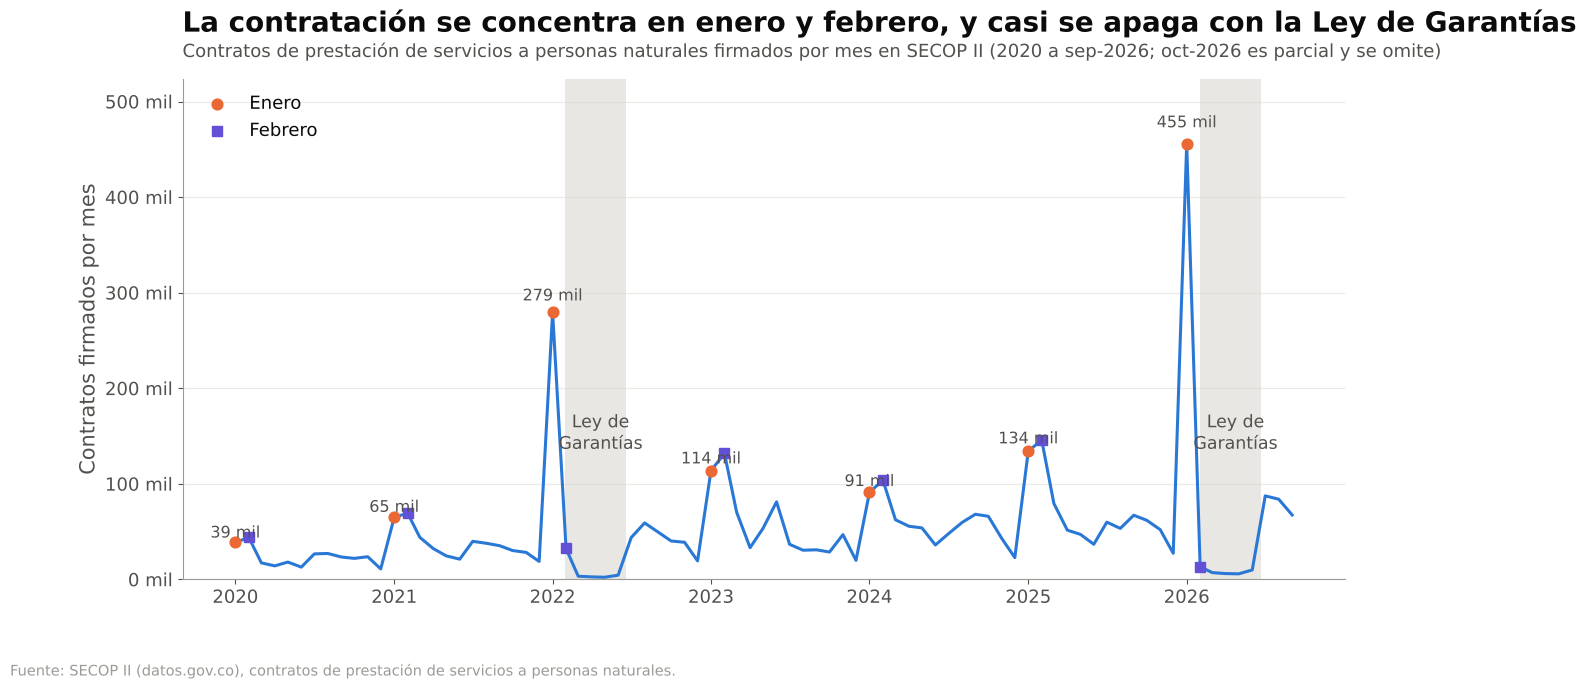

{'enero_por_anio': {'2020': 38604,
  '2021': 64735,
  '2022': 279469,
  '2023': 113876,
  '2024': 90881,
  '2025': 134252,
  '2026': 455420},
 'febrero_por_anio': {'2020': 43864,
  '2021': 69296,
  '2022': 32293,
  '2023': 131721,
  '2024': 103952,
  '2025': 145675,
  '2026': 13212},
 'mes_pico_ene_feb': {2020: 'febrero',
  2021: 'febrero',
  2022: 'enero',
  2023: 'febrero',
  2024: 'febrero',
  2025: 'febrero',
  2026: 'enero'},
 'max_mes': '2026-01-01',
 'max_valor': 455420,
 'promedio_mar_jun_2022': 3091.5,
 'promedio_mar_jun_2023': 59511.5,
 'promedio_feb_jun_2026': 8371.0,
 'promedio_feb_jun_2025': 72052.4}

In [8]:
firmas = pd.concat([pd.read_parquet(DATA_DIR / f'secop_ps_{a}.parquet', columns=['fecha_de_firma'])
                    for a in range(2020, 2027)])
serie = firmas.fecha_de_firma.dt.to_period('M').value_counts().sort_index()
serie = serie[serie.index <= pd.Period('2026-09', 'M')]   # oct-2026 es parcial (hasta el 19-oct): se excluye
serie.index = serie.index.to_timestamp()
serie.rename('contratos_firmados').to_csv(TABLAS / '02_serie_mensual_firmas.csv')
del firmas
eneros = serie[serie.index.month == 1]
print('Contratos firmados en enero:'); print(eneros)
feb = serie[serie.index.month == 2]
pico = pd.DataFrame({'enero': eneros.values, 'febrero': feb.reindex(eneros.index + pd.DateOffset(months=1)).values},
                    index=eneros.index.year)
pico['mes_pico_ene_feb'] = np.where(pico.enero >= pico.febrero, 'enero', 'febrero')
print(pico)

fig, ax = plt.subplots(figsize=(15, 6.5))
# Ley de Garantías: restricción a la contratación directa desde 4 meses antes de la elección presidencial hasta la
# segunda vuelta (aprox. 29-ene a 19-jun de 2022 y 31-ene a 21-jun de 2026)
for ini, fin in [('2022-01-29', '2022-06-19'), ('2026-01-31', '2026-06-21')]:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=COLOR['gris_claro'], alpha=0.6, lw=0)
    ax.text(pd.Timestamp(ini) + (pd.Timestamp(fin) - pd.Timestamp(ini)) / 2 + pd.Timedelta(days=12), serie.max() * 0.30, 'Ley de\nGarantías',
            ha='center', fontsize=12.5, color=COLOR['tinta2'])
ax.plot(serie.index, serie.values, color=COLOR['azul'], lw=2.2)
ax.scatter(eneros.index, eneros.values, color=COLOR['naranja'], s=60, zorder=3, label='Enero')
ax.scatter(feb.index, feb.values, color=COLOR['violeta'], s=45, zorder=3, marker='s', label='Febrero')
for d, v in eneros.items():
    ax.text(d, v * 1.03, f'{num(v/1000)} mil', ha='center', va='bottom', fontsize=11.5, color=COLOR['tinta2'])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f'{num(x/1000)} mil'))
ax.set_ylim(0, serie.max() * 1.15); ax.legend(loc='upper left')
ax.set_ylabel('Contratos firmados por mes')
titulo(ax, 'La contratación se concentra en enero y febrero, y casi se apaga con la Ley de Garantías',
       'Contratos de prestación de servicios a personas naturales firmados por mes en SECOP II (2020 a sep-2026; oct-2026 es parcial y se omite)')
fuente(fig); guardar(fig, '02_serie_mensual_contratos_firmados'); plt.show()
R['serie_mensual'] = {'enero_por_anio': {str(k.year): int(v) for k, v in eneros.items()},
                      'febrero_por_anio': {str(k.year): int(v) for k, v in feb.items()},
                      'mes_pico_ene_feb': pico.mes_pico_ene_feb.to_dict(),
                      'max_mes': str(serie.idxmax().date()), 'max_valor': int(serie.max()),
                      'promedio_mar_jun_2022': float(serie['2022-03':'2022-06'].mean()),
                      'promedio_mar_jun_2023': float(serie['2023-03':'2023-06'].mean()),
                      'promedio_feb_jun_2026': float(serie['2026-02':'2026-06'].mean()),
                      'promedio_feb_jun_2025': float(serie['2025-02':'2025-06'].mean())}
R['serie_mensual']

**Lectura.** La contratación se concentra en **enero y febrero**, cuando las entidades renuevan contratos con el
presupuesto nuevo. En los años normales el pico es febrero (ver la tabla). En 2022 y 2026, en cambio, hay un enero
gigante seguido de un vacío. La Ley de Garantías prohíbe la contratación directa desde cuatro meses antes de la
elección presidencial (desde finales de enero), así que las entidades adelantan todo a enero. Ese patrón de "pico y vacío"
es la causa estructural de los huecos en las trayectorias.

## 7. ¿Cuántos cotizan sobre el mínimo?
Un independiente cotiza sobre el 40% de su honorario, pero nunca menos de 1 SMMLV. Quien gana hasta 2,5 SMMLV
cotiza sobre el mínimo: su pensión, si llega, sería de salario mínimo.

Figura guardada: ../outputs/figs/02_cotiza_sobre_minimo.png


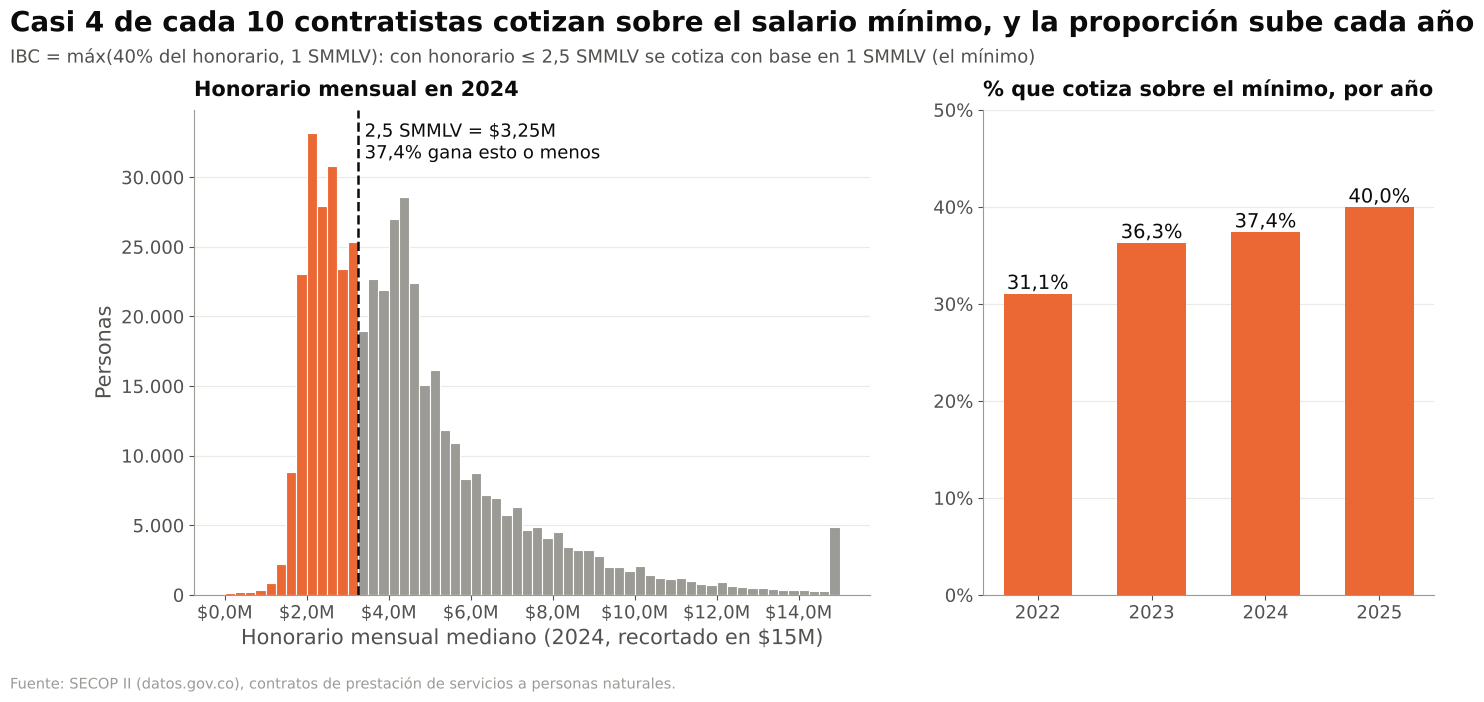

In [9]:
pm = pa.groupby('anio').cotiza_minimo.mean()
umbral = {a: SMMLV[a] / FRACCION_IBC for a in pm.index}
fig, axs = plt.subplots(1, 2, figsize=(16, 6.3), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axs[0]
h = p24.honorario_mensual_mediano.clip(upper=15e6)
ax.hist(h, bins=np.arange(0, 15.25e6, 0.25e6), color=COLOR['gris'], edgecolor='white', linewidth=0.8)
ax.hist(h[p24.cotiza_minimo == 1], bins=np.arange(0, 15.25e6, 0.25e6), color=COLOR['naranja'], edgecolor='white', linewidth=0.8)
ax.axvline(umbral[2024], color=COLOR['tinta'], ls='--', lw=1.8)
ax.text(umbral[2024] * 1.05, ax.get_ylim()[1] * 0.9, f'2,5 SMMLV = ${num(umbral[2024]/1e6, 2)}M\n'
        f'{pct(pm[2024],1)} gana esto o menos', fontsize=13)
ax.xaxis.set_major_formatter(FuncFormatter(pesos_millones)); ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: num(x)))
ax.set_xlabel('Honorario mensual mediano (2024, recortado en $15M)'); ax.set_ylabel('Personas')
ax.set_title('Honorario mensual en 2024', fontsize=15, pad=10)
ax = axs[1]
ax.bar(pm.index.astype(str), pm.values, color=COLOR['naranja'], width=0.6)
for i, v in enumerate(pm.values):
    ax.text(i, v, pct(v), ha='center', va='bottom', fontsize=14)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 0.5)
ax.set_title('% que cotiza sobre el mínimo, por año', fontsize=15, pad=10)
fig.suptitle(f'Casi 4 de cada 10 contratistas cotizan sobre el salario mínimo, y la proporción sube cada año',
             x=0.01, ha='left', fontsize=20, fontweight='bold', y=1.04)
fig.text(0.01, 0.955, 'IBC = máx(40% del honorario, 1 SMMLV): con honorario ≤ 2,5 SMMLV se cotiza con base en 1 SMMLV (el mínimo)',
         fontsize=13, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '02_cotiza_sobre_minimo'); plt.show()
R['cotiza_minimo_por_anio'] = pm.to_dict()
R['umbral_honorario_2_5_smmlv'] = umbral

**Ojo:** el % sube año a año en parte porque el salario mínimo creció más rápido que los honorarios
(el SMMLV pasó de $1,0M en 2022 a $1,42M en 2025, +42%; el honorario mediano subió menos, ver tabla de evolución).

In [10]:
crec = {'smmlv_2022_2025': SMMLV[2025] / SMMLV[2022] - 1,
        'honorario_mediano_2022_2025': por_anio.honorario_mediano[2025] / por_anio.honorario_mediano[2022] - 1}
print({k: pct(v) for k, v in crec.items()})
R['crecimiento_2022_2025'] = crec
R['por_anio'] = {int(a): {str(k): float(v) for k, v in f.items()} for a, f in por_anio.iterrows()}
guardar_resultados('02_exploracion', R)

{'smmlv_2022_2025': '42,4%', 'honorario_mediano_2022_2025': '21,1%'}
resultados.json -> sección "02_exploracion" actualizada
